# 02 — 离散隐变量：直接 MLE 与 EM
仍然使用相同二维数据。主动定义 $p(x=k)=\pi_k$、$p(y|x=k)=\mathcal N(y;\mu_k,\sigma^2 I)$，固定 $\sigma=0.45$，未知参数为混合权重和均值。类别 $x$ 不可观测。联合密度由乘法得到；边缘密度由有限求和得到；后验由归一化得到。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.stats import norm, multivariate_normal
rng = np.random.default_rng(42)
# 仅用于制造观测数据；训练代码不使用真实类别或真实参数。
centers = np.array([[-2., 0.], [2., 0.], [0., 3.]])
y = centers[rng.integers(0, 3, 900)] + 0.45*rng.normal(size=(900, 2))
def compare(samples):
    fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)
    for a, data, title in zip(ax, [y, samples], ['Observed', 'Generated']):
        a.scatter(*data.T, s=5, alpha=.5); a.set_title(title); a.set_aspect('equal')
    plt.show()


In [2]:
sigma = .45
# 避免初始中心集中在同一簇；两种优化使用同一初值。
mu0 = np.array([[-1., 0.], [1., 0.], [0., 2.]])
def probabilities(y, mu, pi):
    log_prior = np.log(pi)                       # [K]
    log_conditional = norm.logpdf(y[:,None,:], mu, sigma).sum(-1) # [N,K]
    log_joint = log_conditional + log_prior
    log_marginal = logsumexp(log_joint, axis=1)
    log_posterior = log_joint - log_marginal[:,None]
    return log_prior, log_conditional, log_joint, log_marginal, log_posterior
pi0 = np.ones(3)/3
parts = probabilities(y, mu0, pi0)
for name, a in zip(['prior','conditional','joint','marginal','posterior'], parts):
    print(name, a.shape, np.exp(a[0]))
assert np.allclose(np.exp(parts[-1]).sum(1), 1)

prior (3,) 0.3333333333333333
conditional (900, 3) [1.69250472e-01 3.68241460e-09 8.45886265e-09]
joint (900, 3) [5.64168242e-02 1.22747153e-09 2.81962088e-09]
marginal (900,) 0.056416828210240424
posterior (900, 3) [9.99999928e-01 2.17571879e-08 4.99783659e-08]


## 直接最大似然
优化 $\sum_i\log\sum_k\pi_k p(y_i|k)$。使用 PyTorch 自动微分；没有任何后验近似。

In [3]:
import torch
torch.set_num_threads(1)
torch.manual_seed(42)
Y = torch.tensor(y, dtype=torch.float64)
mu = torch.nn.Parameter(torch.tensor(mu0.copy()))
logits = torch.nn.Parameter(torch.zeros(3, dtype=torch.float64))
opt = torch.optim.Adam([mu, logits], lr=.05)
mle_history = []
for _ in range(150):
    log_cond = torch.distributions.Normal(mu, sigma).log_prob(Y[:,None,:]).sum(-1)
    ll = torch.logsumexp(log_cond + logits.log_softmax(0), dim=1).mean()
    opt.zero_grad(); (-ll).backward(); opt.step()
    mle_history.append(ll.item())
mu_mle = mu.detach().numpy(); pi_mle = logits.softmax(0).detach().numpy()
print(mu_mle, pi_mle)

[[-2.01845789 -0.03657694]
 [ 1.96484557 -0.05059679]
 [-0.00562701  2.9956356 ]] [0.33778285 0.31221381 0.35000333]


## EM：同一个模型，同一个目标
E 步：$r_{ik}=p(x=k|y_i;\theta_{old})$。M 步最大化 $\sum_{i,k}r_{ik}\log p_\theta(y_i,k)$，对权重和均值有解析解。E 步的责任度在 M 步固定不变。

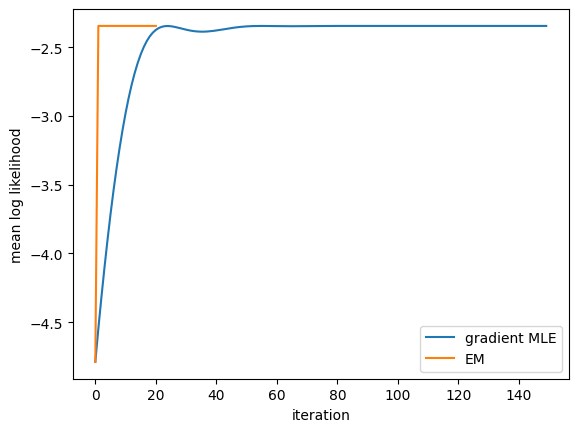

[[-2.01826033 -0.03658497]
 [ 1.964977   -0.05057951]
 [-0.00564098  2.99557747]] [0.33778076 0.31222173 0.34999751]


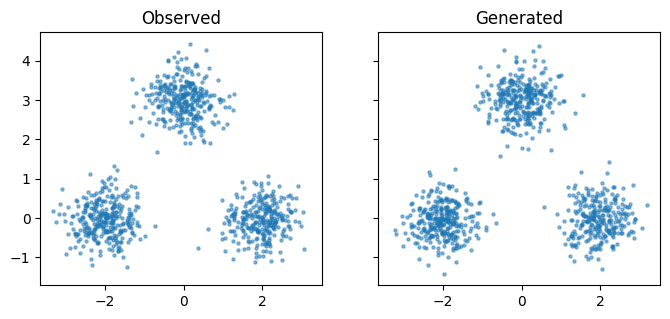

In [4]:
mu, pi = mu0.copy(), pi0.copy()
em_history = [probabilities(y,mu,pi)[3].mean()]
for _ in range(20):
    r = np.exp(probabilities(y, mu, pi)[-1])
    pi = r.mean(0)
    mu = r.T @ y / r.sum(0)[:,None]
    em_history.append(probabilities(y,mu,pi)[3].mean())
assert np.min(np.diff(em_history)) > -1e-9
plt.plot(mle_history,label='gradient MLE'); plt.plot(em_history,label='EM'); plt.legend(); plt.xlabel('iteration'); plt.ylabel('mean log likelihood'); plt.show()
print(mu, pi)
compare(mu[rng.choice(3,len(y),p=pi)] + sigma*rng.normal(size=y.shape))

EM 并未消除边缘化：这里的 E 步本来就容易。它将 M 步改写为加权估计。迭代次数不能直接代表运行时间。改变初始中心或 sigma，观察局部最优和拟合结果。